[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_3_Analisis_Exploratorio.ipynb)

# Fase 3. Análisis exploratorio de datos

Primero reviso la calidad de los datos y delimito la muestra analítica con límites de 1,5 × RIC calculados en entrenamiento. Después describo y comparo las cinco propiedades fisicoquímicas en los compuestos que permanecen en train. La clase DILI y la proporción de cada grupo se resumen en esa misma muestra; test se mantiene reservado para la evaluación final de los modelos.

## 3.1. Lectura de los datos

Leo los CSV preparados en la fase anterior desde la carpeta pública del proyecto. Así puedo ejecutar este notebook sin subir archivos manualmente.

In [1]:
%pip -q install rdkit


In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
dilist['nombre_normalizado'] = dilist['CompoundName'].astype('string').str.strip().str.casefold()  # Quito espacios laterales para evitar falsos no encontrados.
estructuras['nombre_normalizado'] = estructuras['CompoundName'].astype('string').str.strip().str.casefold()  # Creo la misma clave normalizada en el mapa.
datos = dilist.merge(estructuras.drop(columns='CompoundName'), on='nombre_normalizado', how='left')  # Uno por nombre normalizado sin perder la etiqueta original.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /content/datos_dili
Descriptores numéricos disponibles: 218


## 3.2. Control de calidad y delimitación de la muestra

Antes de los análisis estadísticos reviso los valores ausentes, los duplicados, la cobertura de estructuras y las etiquetas contradictorias. Para delimitar el conjunto que se utilizará en los análisis posteriores, calculo con entrenamiento los límites de 1,5 veces el rango intercuartílico (RIC) para MolWt, MolLogP, donantes, aceptores y TPSA. Retiro de train y test los compuestos que exceden al menos uno de esos límites; los límites no se vuelven a estimar con test.

In [3]:
# Selecciono las cinco propiedades usadas para el filtro y los análisis.
variables = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Defino las variables fisicoquímicas.
variables = [variable for variable in variables if variable in train_df.columns]  # Confirmo que estén disponibles.

# Reviso los valores ausentes en el conjunto molecular.
calidad = pd.DataFrame({'nulos': datos_limpios.isna().sum(), 'porcentaje_nulos': (100 * datos_limpios.isna().mean()).round(1)})  # Resumo los nulos.
display(calidad.sort_values('porcentaje_nulos', ascending=False).head(12))  # Muestro las columnas con más ausencias.
print('Nombres sin estructura inequívoca:', datos['InChIKey'].isna().sum())  # Informo la cobertura estructural.
print('Nombres repetidos en DILIst:', dilist['CompoundName'].duplicated().sum())  # Reviso nombres duplicados.
print('InChIKey repetidas en train:', train_df['InChIKey'].duplicated().sum())  # Reviso estructuras duplicadas.
print('Filas con etiquetas contradictorias:', len(datos_conflicto))  # Informo conflictos de etiqueta.

# Calculo los límites de 1,5 × RIC solo con train.
q1 = train_df[variables].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_df[variables].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
lim_inf = q1 - 1.5 * ric  # Defino límites inferiores.
lim_sup = q3 + 1.5 * ric  # Defino límites superiores.
fuera_train = train_df[variables].lt(lim_inf) | train_df[variables].gt(lim_sup)  # Marco extremos en train.
fuera_test = test_df[variables].lt(lim_inf) | test_df[variables].gt(lim_sup)  # Aplico los mismos límites a test.

# Resumo los límites y cuántos registros exceden cada uno.
tabla_outliers = pd.DataFrame({'límite inferior': lim_inf, 'límite superior': lim_sup, 'train': fuera_train.sum(), 'test': fuera_test.sum()})  # Organizo recuentos.
tabla_outliers['train (%)'] = (100 * tabla_outliers['train'] / len(train_df)).round(1)  # Calculo porcentajes en train.
tabla_outliers['test (%)'] = (100 * tabla_outliers['test'] / len(test_df)).round(1)  # Calculo porcentajes en test.
display(tabla_outliers.round(2))  # Muestro umbrales y recuentos.

# Excluyo los compuestos que superan al menos un límite.
mask_outlier_train = fuera_train.any(axis=1)  # Marco filas extremas en train.
mask_outlier_test = fuera_test.any(axis=1)  # Marco filas extremas en test.
train_analisis = train_df.loc[~mask_outlier_train].copy()  # Creo el train que usaré en los análisis.
test_analisis = test_df.loc[~mask_outlier_test].copy()  # Creo el test filtrado para las fases de modelado.

# Informo cuántas observaciones se retiran de cada partición.
print(f"Train: retiro {mask_outlier_train.sum()} de {len(train_df)} compuestos ({100 * mask_outlier_train.mean():.1f}%).")  # Cuantifico la retirada.
print(f"Test: retiro {mask_outlier_test.sum()} de {len(test_df)} compuestos ({100 * mask_outlier_test.mean():.1f}%).")  # Cuantifico la retirada.

# Compruebo si el filtro modifica el balance de clases en train.
balance_train = pd.DataFrame([{'n inicial': len(train_df), 'n filtrado': len(train_analisis), 'DILI positiva inicial (%)': 100 * train_df['DILI'].mean(), 'DILI positiva filtrada (%)': 100 * train_analisis['DILI'].mean()}])  # Resumo solo entrenamiento.
display(balance_train.round(1))  # Muestro el balance antes y después en train.
print(f"En test quedan {len(test_analisis)} de {len(test_df)} compuestos tras aplicar los límites aprendidos con train.")  # Informo el tamaño sin revisar sus etiquetas.

print('Los límites se estiman con train y se aplican sin cambios a test.')  # Explico cómo se evita recalcularlos con test.

,nulos,porcentaje_nulos
Routes_of_Administration,252,21.3
BCUT2D_MWLOW,31,2.6
BCUT2D_CHGHI,31,2.6
BCUT2D_CHGLO,31,2.6
BCUT2D_LOGPHI,31,2.6
BCUT2D_LOGPLOW,31,2.6
BCUT2D_MRHI,31,2.6
BCUT2D_MRLOW,31,2.6
BCUT2D_MWHI,31,2.6
MinPartialCharge,3,0.3


Nombres sin estructura inequívoca: 95
Nombres repetidos en DILIst: 0
InChIKey repetidas en train: 0
Filas con etiquetas contradictorias: 0


,límite inferior,límite superior,train,test,train (%),test (%)
MolWt,-1.01,687.90,69,24,7.3,10.1
MolLogP,-3.82,8.22,38,15,4.0,6.3
NumHDonors,-2.00,6.00,56,14,5.9,5.9
NumHAcceptors,-1.50,10.50,92,26,9.7,11.0
TPSA,-59.66,220.06,54,13,5.7,5.5


Train: retiro 115 de 947 compuestos (12.1%).
Test: retiro 36 de 237 compuestos (15.2%).


,n inicial,n filtrado,DILI positiva inicial (%),DILI positiva filtrada (%)
0,947,832,61.5,63.1


En test quedan 201 de 237 compuestos tras aplicar los límites aprendidos con train.
Los límites se estiman con train y se aplican sin cambios a test.


### Lectura de calidad y extremos

La revisión detectó 95 nombres sin estructura utilizable entre los 1.279 registros de DILIst y 252 valores ausentes en la vía de administración (21,3 % de las 1.184 estructuras). Ocho descriptores BCUT2D presentan 31 ausencias cada uno (2,6 %) y tres descriptores de carga parcial, tres ausencias cada uno (0,3 %). No se encontraron nombres repetidos, InChIKey duplicadas en train ni etiquetas contradictorias.

Los límites de 1,5 × RIC se calcularon en train. El filtro retiró 115 de 947 compuestos de entrenamiento (12,1 %) y 36 de 237 de prueba (15,2 %). En train, la proporción DILI positiva pasó de 61,5 % a 63,1 %; se excluyeron 57 positivos y 58 negativos, por lo que el cambio de composición fue pequeño.

Fondaparinux sodium fue el ejemplo que superó los cinco límites: su peso molecular es 1.728,09 Da, presenta 9 donantes y 49 aceptores de puentes de hidrógeno, TPSA de 833,78 y MolLogP de −49,12. Es una estructura real con un perfil muy distinto del de la mayoría de los compuestos del conjunto. Su exclusión no indica un error: delimita el espacio químico al que se refieren los análisis posteriores.

,CompoundName,DILI,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,criterio
558,fondaparinux sodium,1,1728.09,-49.12,9.0,49.0,833.78,"MolWt, MolLogP, NumHDonors, NumHAcceptors, TPSA"


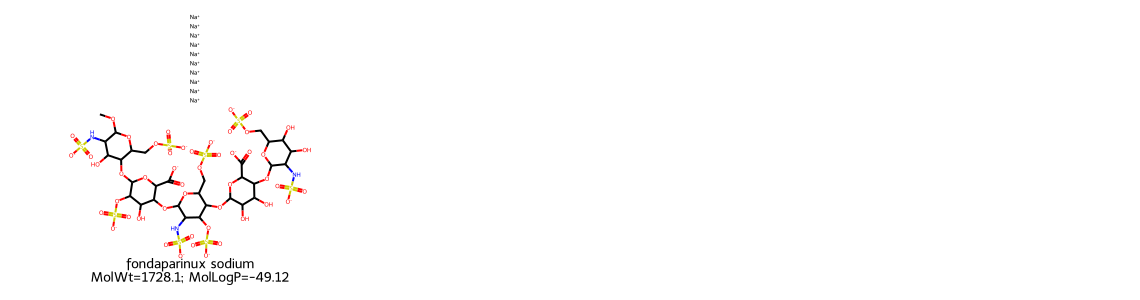

La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.


In [4]:
# Selecciono tres compuestos de train marcados por el filtro.
compuestos_atipicos = train_df.loc[mask_outlier_train].copy()  # Reúno las filas que se retirarán.
nombres_ejemplo = ['atazanavir', 'montelukast', 'fondaparinux sodium']  # Elijo perfiles moleculares distintos.
ejemplos_atipicos = compuestos_atipicos[compuestos_atipicos['CompoundName'].str.casefold().isin(nombres_ejemplo)].copy()  # Localizo los ejemplos.
ejemplos_atipicos['criterio'] = ejemplos_atipicos.apply(lambda fila: ', '.join([v for v in variables if fuera_train.loc[fila.name, v]]), axis=1)  # Indico qué propiedad excede el límite.
columnas_ejemplo = ['CompoundName', 'DILI', 'MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA', 'criterio']  # Selecciono los datos a mostrar.
display(ejemplos_atipicos[columnas_ejemplo].round(2))  # Muestro sus valores.

# Dibujo las estructuras junto al nombre, peso molecular y MolLogP.
from rdkit import Chem  # Leo moléculas desde SMILES.
from rdkit.Chem import Draw  # Dibujo las estructuras químicas.
moleculas = []  # Guardo estructuras válidas.
leyendas = []  # Guardo las etiquetas de cada dibujo.
for _, fila in ejemplos_atipicos.iterrows():  # Recorro los compuestos escogidos.
    mol = Chem.MolFromSmiles(fila['SMILES'])  # Construyo una molécula desde SMILES.
    if mol is not None:  # Compruebo que RDKit la reconoce.
        moleculas.append(mol)  # Añado la estructura.
        leyendas.append(f"{fila['CompoundName']}\nMolWt={fila['MolWt']:.1f}; MolLogP={fila['MolLogP']:.2f}")  # Identifico el dibujo.
if moleculas:  # Compruebo que haya estructuras válidas.
    display(Draw.MolsToGridImage(moleculas, molsPerRow=3, subImgSize=(380, 300), legends=leyendas))  # Muestro las tres juntas.
print('La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.')  # Interpreto los ejemplos.


## 3.3. Análisis univariante de la muestra analítica

Una vez aplicado el filtro, describo las cinco propiedades fisicoquímicas en el conjunto de entrenamiento que permanece. Para cada variable calculo media, mediana, moda, desviación estándar, mínimo, máximo y cuartiles. También resumo las frecuencias absolutas y relativas de las clases DILI en esta misma muestra.

In [5]:
# Selecciono cinco propiedades fisicoquímicas fáciles de interpretar.
variables = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Escojo las variables de Lipinski y TPSA.
variables = [variable for variable in variables if variable in train_analisis.columns]  # Confirmo que estén en el conjunto.

# Calculo las medidas de resumen univariado con entrenamiento.
resumen = train_analisis[variables].describe().T  # Obtengo media, desviación, mínimo, cuartiles y máximo.
resumen['mediana'] = train_analisis[variables].median()  # Añado la mediana.
resumen['moda'] = train_analisis[variables].mode().iloc[0]  # Añado la moda más frecuente.
display(resumen.round(2))  # Muestro el resumen redondeado.
print('Lectura de las medidas:')  # Inicio el comentario de los resultados calculados.
for variable in variables:  # Recorro las propiedades estudiadas.
    print(f"{variable}: mediana {resumen.loc[variable, 'mediana']:.2f}; la mitad central está entre {resumen.loc[variable, '25%']:.2f} y {resumen.loc[variable, '75%']:.2f}.")  # Interpreto centro y dispersión observados.

# Cuento las clases DILI en frecuencia absoluta y relativa.
frecuencias = train_analisis['DILI'].value_counts().sort_index().to_frame('frecuencia')  # Cuento registros por clase.
frecuencias['porcentaje'] = (100 * frecuencias['frecuencia'] / len(train_analisis)).round(1)  # Calculo porcentajes.
frecuencias.index = frecuencias.index.map({0: 'DILI negativa', 1: 'DILI positiva'})  # Pongo nombres legibles.
display(frecuencias)  # Muestro la distribución de clases.
print(f"En train, {frecuencias.loc['DILI positiva', 'porcentaje']:.1f}% tiene etiqueta positiva y {frecuencias.loc['DILI negativa', 'porcentaje']:.1f}% negativa.")  # Comento el balance observado.


,count,mean,std,min,25%,50%,75%,max,mediana,moda
MolWt,832.0,322.44,110.14,18.02,249.00,312.87,390.67,679.86,312.87,135.21
MolLogP,832.0,2.35,2.04,-3.59,1.05,2.55,3.77,7.64,2.55,-3.59
NumHDonors,832.0,1.68,1.37,0.00,1.00,1.00,2.00,6.00,1.00,1.00
NumHAcceptors,832.0,4.07,2.04,0.00,3.00,4.00,5.00,10.00,4.00,3.00
TPSA,832.0,72.41,41.44,0.00,41.55,66.89,99.10,214.02,66.89,3.24


Lectura de las medidas:
MolWt: mediana 312.87; la mitad central está entre 249.00 y 390.67.
MolLogP: mediana 2.55; la mitad central está entre 1.05 y 3.77.
NumHDonors: mediana 1.00; la mitad central está entre 1.00 y 2.00.
NumHAcceptors: mediana 4.00; la mitad central está entre 3.00 y 5.00.
TPSA: mediana 66.89; la mitad central está entre 41.55 y 99.11.


,frecuencia,porcentaje
DILI,,
DILI negativa,307,36.9
DILI positiva,525,63.1


En train, 63.1% tiene etiqueta positiva y 36.9% negativa.


## 3.4. Análisis bivariante y contraste inferencial

Las cajas y las medianas comparan cada propiedad fisicoquímica con la etiqueta DILI en el conjunto filtrado. Después se contrasta formalmente si las distribuciones de esas propiedades difieren entre las dos clases.

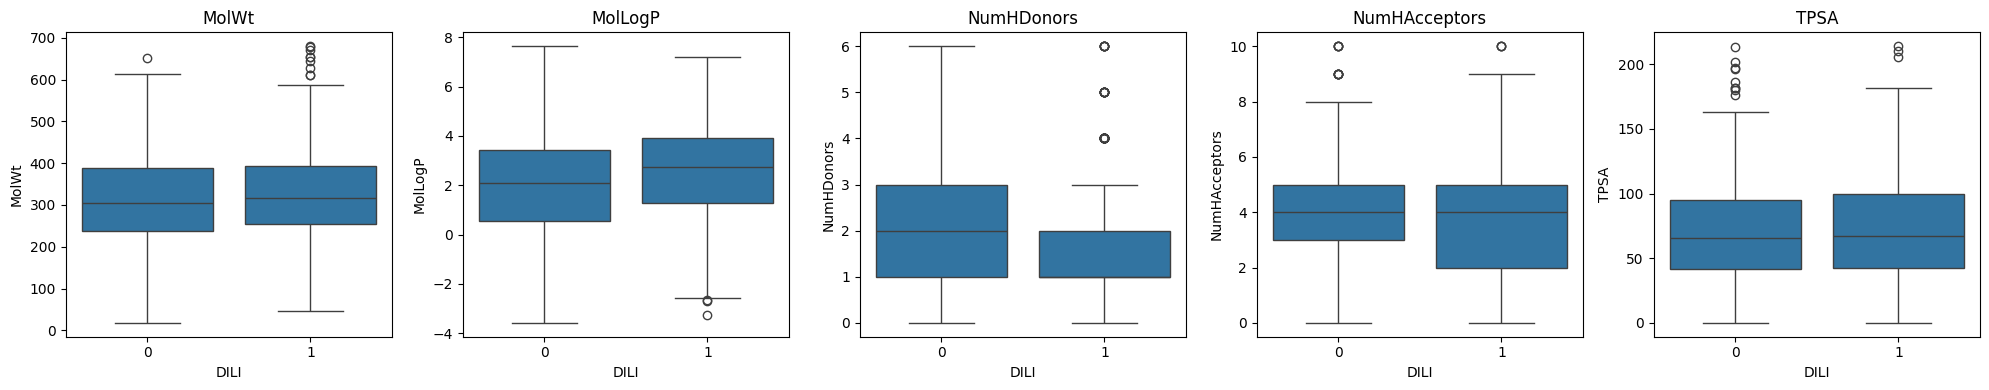

DILI,DILI negativa,DILI positiva,diferencia (positiva − negativa)
MolWt,305.42,317.34,11.93
MolLogP,2.08,2.73,0.65
NumHDonors,2.00,1.00,-1.00
NumHAcceptors,4.00,4.00,0.00
TPSA,65.49,67.51,2.02


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comparo las cinco propiedades entre las clases DILI negativa y positiva.
fig, axes = plt.subplots(1, len(variables), figsize=(4 * len(variables), 4))  # Creo un panel por propiedad.
for ax, variable in zip(axes, variables):  # Recorro las propiedades seleccionadas.
    sns.boxplot(data=train_analisis, x='DILI', y=variable, ax=ax)  # Comparo su distribución por clase.
    ax.set_title(variable)  # Identifico cada panel.
    ax.set_xlabel('DILI')  # Aclaro la codificación de clases.
plt.tight_layout()  # Ajusto los espacios.
plt.show()  # Muestro la comparación bivariada.

# Comparo las medianas para acompañar la lectura de los diagramas.
medianas_clase = train_analisis.groupby('DILI')[variables].median().T  # Calculo una mediana por clase.
medianas_clase['diferencia (positiva − negativa)'] = medianas_clase[1] - medianas_clase[0]  # Calculo el cambio entre grupos.
medianas_clase = medianas_clase.rename(columns={0: 'DILI negativa', 1: 'DILI positiva'})  # Pongo nombres descriptivos.
display(medianas_clase.round(2))  # Muestro las medianas y su diferencia.


### Contraste inferencial entre las clases DILI

Se aplica una prueba bilateral U de Mann–Whitney a cada propiedad para comparar las clases DILI positiva y negativa en el conjunto de entrenamiento posterior al filtro de 1,5 × RIC. Se informa la diferencia de medianas y el delta de Cliff para describir dirección y magnitud; los cinco valores p se ajustan mediante Holm. El contraste se realiza solo en train y test permanece reservado para la evaluación de los modelos.

In [7]:
# Importo la prueba no paramétrica para dos grupos independientes.
from scipy.stats import mannwhitneyu  # Comparo rangos entre DILI negativa y positiva.

# Comparo cada propiedad en el conjunto de entrenamiento posterior al filtro de 1,5 × RIC.
resultados_test = []  # Guardo el resultado de cada contraste.
for variable in variables:  # Recorro MolWt, MolLogP, HBD, HBA y TPSA.
    grupo_negativo = train_analisis.loc[train_analisis['DILI'] == 0, variable].dropna()  # Extraigo DILI negativa.
    grupo_positivo = train_analisis.loc[train_analisis['DILI'] == 1, variable].dropna()  # Extraigo DILI positiva.
    u, p = mannwhitneyu(grupo_positivo, grupo_negativo, alternative='two-sided')  # Contrasto diferencias de distribución.
    delta = 2 * u / (len(grupo_positivo) * len(grupo_negativo)) - 1  # Estimo delta de Cliff con dirección positiva-negativa.
    resultados_test.append({  # Guardo tamaños, medianas, efecto y significación.
        'Propiedad': variable,
        'n negativa': len(grupo_negativo),
        'n positiva': len(grupo_positivo),
        'Mediana negativa': grupo_negativo.median(),
        'Mediana positiva': grupo_positivo.median(),
        'Diferencia de medianas (positiva − negativa)': grupo_positivo.median() - grupo_negativo.median(),
        'U de Mann–Whitney': u,
        'Delta de Cliff': delta,
        'p sin ajustar': p
    })

# Ajusto por las cinco comparaciones para limitar falsos positivos por pruebas múltiples.
tabla_tests = pd.DataFrame(resultados_test)  # Organizo los contrastes en una tabla.
p_valores = tabla_tests['p sin ajustar'].to_numpy()  # Extraigo los cinco valores p.
orden = np.argsort(p_valores)  # Ordeno los valores p de menor a mayor.
p_ordenados = p_valores[orden]  # Mantengo el orden para el ajuste Holm.
p_holm_ordenados = np.maximum.accumulate((len(p_valores) - np.arange(len(p_valores))) * p_ordenados)  # Aplico el ajuste paso a paso de Holm.
p_holm = np.empty_like(p_valores)  # Reservo el resultado en el orden original.
p_holm[orden] = np.clip(p_holm_ordenados, 0, 1)  # Devuelvo los valores ajustados a cada propiedad.
tabla_tests['p ajustado (Holm)'] = p_holm  # Añado la significación ajustada.
tabla_mostrar = tabla_tests.round(4).copy()  # Redondeo las estadísticas sin ocultar diferencias nulas.
for columna in ['p sin ajustar', 'p ajustado (Holm)']:  # Formateo solo los valores p pequeños.
    tabla_mostrar[columna] = tabla_tests[columna].map(lambda valor: '< 0.0001' if valor < 0.0001 else f'{valor:.4f}')  # Evito mostrar p como cero.
display(tabla_mostrar)  # Muestro las diferencias de medianas y los p con formatos distintos.  # Muestro resultados y tamaño del efecto.

# Comento la dirección y el resultado de cada contraste sin confundir significación con magnitud.
for _, fila in tabla_tests.iterrows():  # Recorro la tabla final.
    direccion = 'mayor' if fila['Delta de Cliff'] > 0 else 'menor'  # Indico qué clase tiende a tener rangos mayores.
    lectura = 'evidencia de diferencia' if fila['p ajustado (Holm)'] < 0.05 else 'sin evidencia suficiente de diferencia'  # Interpreto el p ajustado.
    p_ajustado = fila['p ajustado (Holm)']  # Recupero el valor p corregido.
    p_texto = '<0.0001' if p_ajustado < 0.0001 else f'{p_ajustado:.4f}'  # Evito presentar p pequeños como cero.
    print(f"{fila['Propiedad']}: valores generalmente {direccion} en DILI positiva; delta de Cliff = {fila['Delta de Cliff']:.3f}; {lectura} tras el ajuste Holm (p {p_texto}).")  # Relaciono inferencia y efecto.


,Propiedad,n negativa,n positiva,Mediana negativa,Mediana positiva,Diferencia de medianas (positiva − negativa),U de Mann–Whitney,Delta de Cliff,p sin ajustar,p ajustado (Holm)
0,MolWt,307,525,305.4180,317.3440,11.9260,85428.0,0.0601,0.1479,0.5916
1,MolLogP,307,525,2.0811,2.7283,0.6472,93449.0,0.1596,0.0001,0.0006
2,NumHDonors,307,525,2.0000,1.0000,-1.0000,77224.5,-0.0417,0.3000,0.9001
3,NumHAcceptors,307,525,4.0000,4.0000,0.0000,80222.0,-0.0045,0.9120,1.0000
4,TPSA,307,525,65.4900,67.5100,2.0200,82320.5,0.0215,0.6045,1.0000


MolWt: valores generalmente mayor en DILI positiva; delta de Cliff = 0.060; sin evidencia suficiente de diferencia tras el ajuste Holm (p 0.5916).
MolLogP: valores generalmente mayor en DILI positiva; delta de Cliff = 0.160; evidencia de diferencia tras el ajuste Holm (p 0.0006).
NumHDonors: valores generalmente menor en DILI positiva; delta de Cliff = -0.042; sin evidencia suficiente de diferencia tras el ajuste Holm (p 0.9001).
NumHAcceptors: valores generalmente menor en DILI positiva; delta de Cliff = -0.005; sin evidencia suficiente de diferencia tras el ajuste Holm (p 1.0000).
TPSA: valores generalmente mayor en DILI positiva; delta de Cliff = 0.022; sin evidencia suficiente de diferencia tras el ajuste Holm (p 1.0000).


La prueba evalúa si las distribuciones de rangos difieren entre las clases; no demuestra causalidad ni mide por sí sola la importancia toxicológica. Un valor p pequeño puede acompañar una diferencia de magnitud reducida, por lo que se interpreta junto con la diferencia de medianas y el delta de Cliff. Al haberse aplicado el mismo filtro a toda la muestra analítica, las comparaciones son coherentes con la población empleada en los modelos y conglomerados.

### Correlaciones entre propiedades y asociación exploratoria con DILI

Se calculan correlaciones de Spearman entre las cinco propiedades y asociaciones entre los descriptores moleculares y DILI usando el train filtrado. Los coeficientes describen asociaciones monotónicas; no prueban causalidad. Los resultados se interpretan junto con las diferencias de distribución y los contrastes inferenciales anteriores.

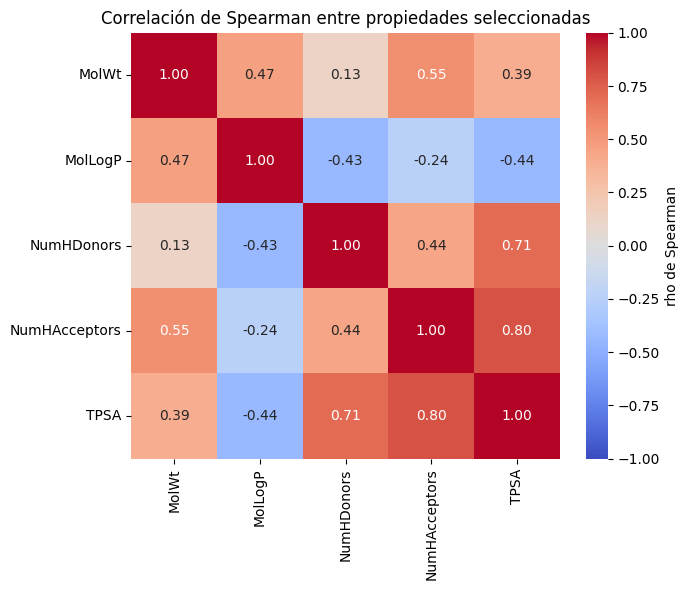

,descriptor,Spearman con DILI,n observaciones
0,BCUT2D_MRHI,0.214566,822
1,FractionCSP3,-0.205735,832
2,BCUT2D_LOGPLOW,0.178020,822
3,fr_Al_OH,-0.176726,832
4,SMR_VSA10,0.173077,832
5,VSA_EState9,-0.163998,832
6,fr_quatN,-0.160338,832
7,SlogP_VSA2,-0.158059,832
8,NumBridgeheadAtoms,-0.147530,832
9,fr_Ndealkylation1,-0.138615,832


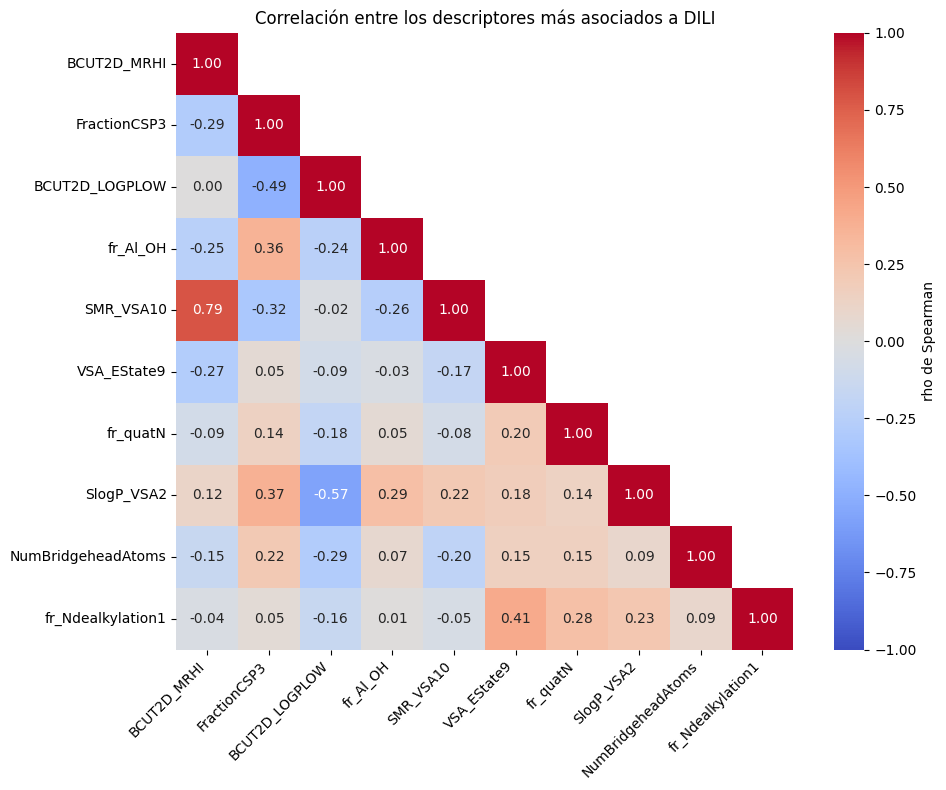

DILI,0,1,diferencia positiva-negativa
MolWt,305.42,317.34,11.93
TPSA,65.49,67.51,2.02
NumHDonors,2.00,1.00,-1.00
MolLogP,2.08,2.73,0.65
NumHAcceptors,4.00,4.00,0.00


,Spearman con DILI
MolLogP,0.133386
MolWt,0.050201
NumHDonors,-0.035958
TPSA,0.017973
NumHAcceptors,-0.003838


Entre las cinco propiedades, MolLogP tiene la mayor asociación monotónica con DILI (rho = 0.13).
Las correlaciones describen asociaciones; no demuestran causalidad.


In [8]:
# Calculo la correlación entre las cinco propiedades fisicoquímicas del EDA.
correlaciones = train_analisis[variables].corr(method='spearman')  # Calculo Spearman con entrenamiento.
fig, ax = plt.subplots(figsize=(7, 6))  # Creo una figura independiente para esta matriz.
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Represento una sola barra de color.
ax.set_title('Correlación de Spearman entre propiedades seleccionadas')  # Titulo el mapa.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Muestro la matriz.

# Reviso la asociación de los descriptores con DILI y retiro columnas con demasiados valores ausentes.
variables_amplias = [variable for variable in DESCRIPTORES if variable not in ['DILI', 'DILIST_ID'] and train_analisis[variable].notna().mean() >= 0.80 and train_analisis[variable].nunique(dropna=True) > 1]  # Filtro propiedades con suficientes observaciones.
correlacion_dili = train_analisis[variables_amplias + ['DILI']].corr(method='spearman', min_periods=100)['DILI'].drop('DILI').dropna()  # Calculo asociación con al menos cien pares.
top_asociaciones = correlacion_dili.abs().sort_values(ascending=False).head(15)  # Selecciono las quince asociaciones mayores.
resumen_asociaciones = pd.DataFrame({'descriptor': top_asociaciones.index, 'Spearman con DILI': correlacion_dili.loc[top_asociaciones.index].values, 'n observaciones': train_analisis[top_asociaciones.index].notna().sum().values})  # Añado el tamaño de cada comparación.
display(resumen_asociaciones)  # Muestro las asociaciones y sus tamaños.

# Represento la correlación entre los diez descriptores con mayor asociación a DILI.
top_diez = top_asociaciones.head(10).index.tolist()  # Selecciono diez variables para la matriz.
matriz_amplia = train_analisis[top_diez].corr(method='spearman', min_periods=100)  # Calculo correlaciones con al menos cien observaciones comunes.
fig, ax = plt.subplots(figsize=(10, 8))  # Creo una segunda figura independiente.
mascara = np.triu(np.ones_like(matriz_amplia, dtype=bool), k=1)  # Oculto la mitad superior repetida.
sns.heatmap(matriz_amplia, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Dibujo una matriz legible con una barra.
ax.set_title('Correlación entre los descriptores más asociados a DILI')  # Titulo la segunda matriz.
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')  # Giro los nombres para que no se solapen.
plt.tight_layout()  # Ajusto etiquetas y márgenes.
plt.show()  # Muestro la matriz amplia.

# Comparo las medianas de las cinco propiedades del EDA entre las clases DILI.
medianas = train_analisis.groupby('DILI')[variables].median().T  # Calculo medianas por clase.
medianas['diferencia positiva-negativa'] = medianas[1] - medianas[0]  # Calculo una diferencia descriptiva.
display(medianas.sort_values('diferencia positiva-negativa', key=abs, ascending=False).round(2))  # Ordeno por diferencia absoluta.

# Calculo la asociación de las cinco propiedades seleccionadas con DILI.
relacion = train_analisis[variables + ['DILI']].corr(method='spearman')['DILI'].drop('DILI')  # Extraigo la correlación con la etiqueta.
display(relacion.sort_values(key=abs, ascending=False).to_frame('Spearman con DILI'))  # Muestro las asociaciones seleccionadas.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación de mayor magnitud.
print(f"Entre las cinco propiedades, {variable_mayor} tiene la mayor asociación monotónica con DILI (rho = {relacion[variable_mayor]:.2f}).")  # Comento signo y magnitud observados.
print('Las correlaciones describen asociaciones; no demuestran causalidad.')  # Aclaro su alcance.


In [9]:
# Resumo la composición de la muestra analítica final.
proporciones = train_analisis['DILI'].value_counts(normalize=True)  # Calculo proporciones tras el filtro.
print(f"En train filtrado, DILI positiva representa {100 * proporciones.get(1, 0):.1f}% y DILI negativa {100 * proporciones.get(0, 0):.1f}%.")  # Informo el balance analítico.

# Comparo las medianas filtradas de MolLogP por clase.
medianas_logp = train_analisis.groupby('DILI')['MolLogP'].median()  # Calculo una mediana por clase.
print(f"La mediana filtrada de MolLogP es {medianas_logp.get(1, np.nan):.2f} en DILI positiva y {medianas_logp.get(0, np.nan):.2f} en DILI negativa.")  # Comparo las clases.

# Resumo la asociación más alta entre las cinco propiedades seleccionadas.
relacion = train_analisis[variables + ['DILI']].corr(method='spearman')['DILI'].drop('DILI')  # Calculo Spearman en la muestra analítica.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación de mayor magnitud.
print(f"La mayor asociación entre las cinco propiedades es {variable_mayor} (rho = {relacion[variable_mayor]:.2f}).")  # Informo el resultado.
print(f"La muestra analítica contiene {len(train_analisis)} compuestos en train y {len(test_analisis)} en test.")  # Informo el tamaño final.
print('Estas relaciones describen asociaciones y no permiten concluir causalidad.')  # Delimito el alcance.

En train filtrado, DILI positiva representa 63.1% y DILI negativa 36.9%.
La mediana filtrada de MolLogP es 2.73 en DILI positiva y 2.08 en DILI negativa.
La mayor asociación entre las cinco propiedades es MolLogP (rho = 0.13).
La muestra analítica contiene 832 compuestos en train y 201 en test.
Estas relaciones describen asociaciones y no permiten concluir causalidad.


## ¿Qué nos dicen los datos?

Los análisis siguientes se realizaron sobre los 832 compuestos de entrenamiento que permanecieron tras el filtro. La clase positiva representa el 63,1 % (525 compuestos) y la negativa el 36,9 % (307). El filtro eliminó proporciones parecidas de ambas clases, por lo que el balance cambió poco respecto al train inicial.

En el análisis univariante, MolWt presenta una mediana de 312,87 Da y un rango intercuartílico de 249,00 a 390,67 Da. La media (322,44 Da) supera ligeramente la mediana, compatible con una cola hacia masas moleculares mayores. MolLogP tiene una mediana de 2,55 y un rango intercuartílico de 1,05 a 3,77. Los compuestos del centro de la distribución son, en general, moderadamente lipófilos, aunque se conserva variación amplia. La mediana de TPSA es 66,89, con valores centrales entre 41,55 y 99,10; los donantes y aceptores tienen medianas de 1 y 4, respectivamente. Estos resúmenes describen propiedades del conjunto y no determinan por sí solos absorción o toxicidad.

La diferencia más clara entre las clases aparece en MolLogP: la mediana es 2,73 en DILI positivos y 2,08 en negativos, con una diferencia de 0,65. La prueba U de Mann–Whitney mantiene evidencia de diferencia tras el ajuste de Holm (p = 0,0006), aunque el delta de Cliff es pequeño (0,160) y la correlación de Spearman con DILI también es débil (ρ = 0,133). Esto indica una tendencia: los positivos de este conjunto son algo más lipófilos, pero existe un amplio solapamiento entre las clases. Químicamente, la lipofilia puede favorecer la partición en membranas y modificar la distribución o exposición hepática; estos resultados no demuestran que cause lesión ni permiten predecir el riesgo clínico por sí sola.

Para MolWt, la mediana es 317,34 Da en positivos y 305,42 Da en negativos, pero la diferencia es pequeña frente a la variabilidad observada (delta de Cliff = 0,060; p de Holm = 0,5916). Tampoco se encontró evidencia de diferencias para donantes de puentes de hidrógeno (medianas 1 y 2; p = 0,9001), aceptores (mediana 4 en ambas clases; p = 1,0000) o TPSA (67,51 frente a 65,49; p de Holm = 1,0000). Por tanto, en esta muestra filtrada esas propiedades no separan claramente las etiquetas DILI.

Entre los descriptores moleculares, las asociaciones absolutas más altas fueron BCUT2D_MRHI (ρ = 0,215) y FractionCSP3 (ρ = −0,206); ambas siguen siendo modestas. En conjunto, los análisis apoyan una asociación débil entre la etiqueta DILI y algunas características estructurales, con una señal más consistente para MolLogP. La clasificación de DILIst no equivale a una medición de incidencia clínica, y los contrastes describen asociaciones en los compuestos incluidos, no relaciones causales.